# Method 2: optimal transport, per position group

**Question.** Can we fix the *shape* of the low-minute distribution instead of fixing players one at a time?

**Idea in plain words.** High-minute players show how a stat is really spread out. Low-minute players look
too spread out because luck pushes some far up and some far down. Optimal transport (OT) is the cheapest way
to move one pile of values onto another pile. We move each low-minute group onto the high-minute pile,
which squeezes the unrealistic extremes.

* **1-D OT:** one stat at a time. The player at the 90th percentile of a low-minute group gets the 90th-percentile
  value of the reference group.
* **Sinkhorn OT:** moves whole stat profiles at once, so a player's other stats help decide where they land.

**Why per position group.** The reference pile has to come from the same kind of player: a winger's shots/90 should be
compared with other wingers, not with centre backs. Each tactical group gets its own reference, built from the player-seasons
of that group with 900+ minutes in the role.

**Assumption to keep in mind:** low-minute players are assumed to be as good *on average* as the reference
group. If they are really weaker on average, OT slightly overrates them.

**Plan.** *Part A* walks through one group in detail. *Part B* runs every group and compares.

In [1]:
import sys
sys.path.append("../..")  # repo root, so low_minute_player_analysis can be imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from low_minute_player_analysis import common
from low_minute_player_analysis import optimal_transport as otm
from sklearn.decomposition import PCA
sns.set_theme(style="whitegrid", context="notebook")

GENDER = "female"
DEEP_DIVE = "Center Forwards"   # the group we walk through step by step in part A
STAT = common.STAT_COLS[DEEP_DIVE][0]  # the stat we zoom in on in the plots (goals)

con = common.connect()
# One entry per tactical group: player-seasons, per-90 rates, season t -> t+1 pairs.
data = {group: common.prepare_group(con, GENDER, group) for group in common.GROUPS}

overview = pd.DataFrame({
    group: {"player-seasons": len(d.terms),
            "players": d.terms["player_id"].nunique(),
            "with next season": len(d.pairs),
            "median minutes": d.terms["minutes"].median(),
            "share under 250 min": (d.terms["minutes"] < 250).mean()}
    for group, d in data.items()}).T
overview.round(2)

,player-seasons,players,with next season,median minutes,share under 250 min
GK,4958.0,2588.0,1387.0,463.5,0.41
Outside Backs,18798.0,11331.0,2548.0,145.0,0.60
Center Backs,13158.0,7777.0,2811.0,287.0,0.48
Wingers,18827.0,11540.0,482.0,80.0,0.81
Center Forwards,18936.0,11196.0,1534.0,103.0,0.69
Attacking Midfielders,23820.0,13712.0,995.0,100.0,0.74
Central Midfielders,23003.0,13377.0,3098.0,139.0,0.61


# Part A: one group in detail

Center Forwards: reference = 1,172 player-seasons with 900+ minutes


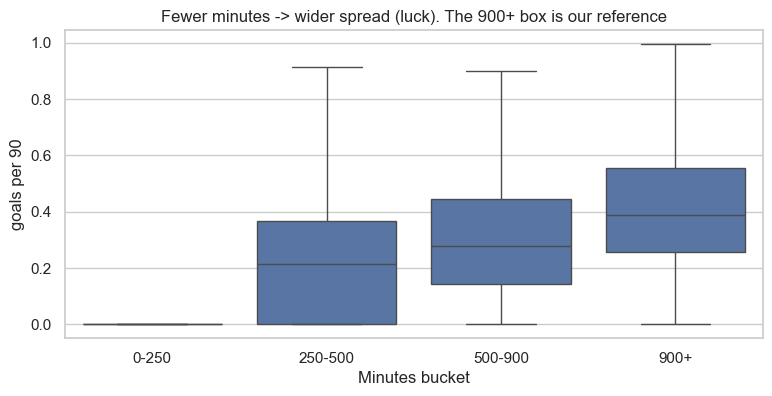

In [2]:
d = data[DEEP_DIVE]
reference = otm.fit_reference(d.all_rates, d.terms["minutes"])
print(f"{DEEP_DIVE}: reference = {len(reference):,} player-seasons with {otm.REFERENCE_MINUTES}+ minutes")

# Spread of the raw stat in each minute bucket. Lower-minute buckets are wider and have longer tails.
frame = pd.DataFrame({STAT: d.all_rates[STAT], "bucket": common.minute_bucket(d.terms["minutes"])})
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=frame, x="bucket", y=STAT, ax=ax, showfliers=False)
ax.set_xlabel("Minutes bucket"); ax.set_ylabel(f"{STAT} per 90")
ax.set_title("Fewer minutes -> wider spread (luck). The 900+ box is our reference")
plt.show()

## A1. 1-D transport, one stat

The plot on the left is the cumulative distribution (the share of players below each value).
After transport, the low-minute curve should land on top of the reference curve.
The plot on the right is the mapping itself: each raw value and where it was moved.
Because the mapping only goes up, players keep their order.

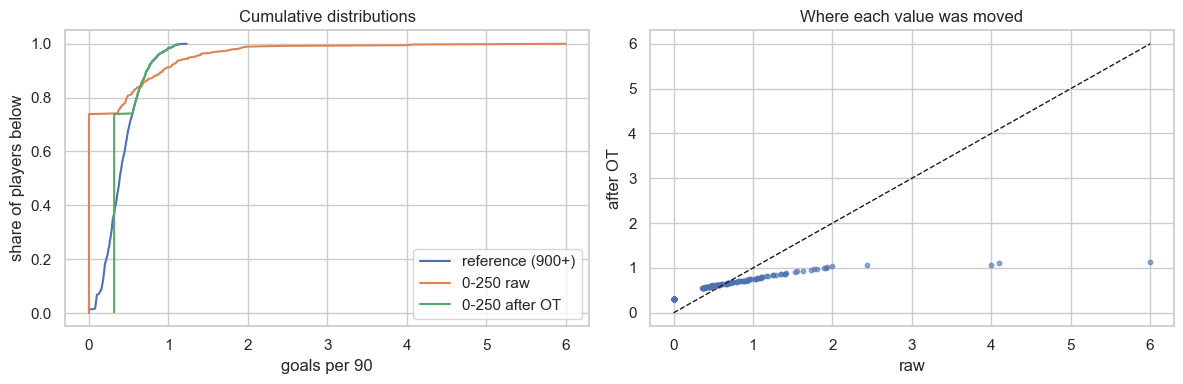

In [3]:
low_bucket = "0-250"
rows = d.pairs.index[common.minute_bucket(d.minutes) == low_bucket]
before = d.raw.loc[rows, STAT]
after = otm.transport_1d(before, reference[STAT])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for values, label in [(reference[STAT], "reference (900+)"), (before, f"{low_bucket} raw"), (after, f"{low_bucket} after OT")]:
    xs = np.sort(values)
    axes[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=label)
axes[0].set_xlabel(f"{STAT} per 90"); axes[0].set_ylabel("share of players below"); axes[0].legend()
axes[0].set_title("Cumulative distributions")

axes[1].scatter(before, after, s=10, alpha=0.6)
axes[1].plot([0, before.max()], [0, before.max()], "k--", linewidth=1)
axes[1].set_xlabel("raw"); axes[1].set_ylabel("after OT"); axes[1].set_title("Where each value was moved")
plt.tight_layout(); plt.show()

## A2. Sinkhorn transport, all stats together

The **coupling** shows where each low-minute player's weight is sent among reference players. A tidy diagonal
band means similar players are matched. A blurry block means everything is pulled toward the average.
Here is a small random sample so it stays readable (players sorted by their goals/90).

C:\Users\zcoch\AppData\Roaming\Python\Python313\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


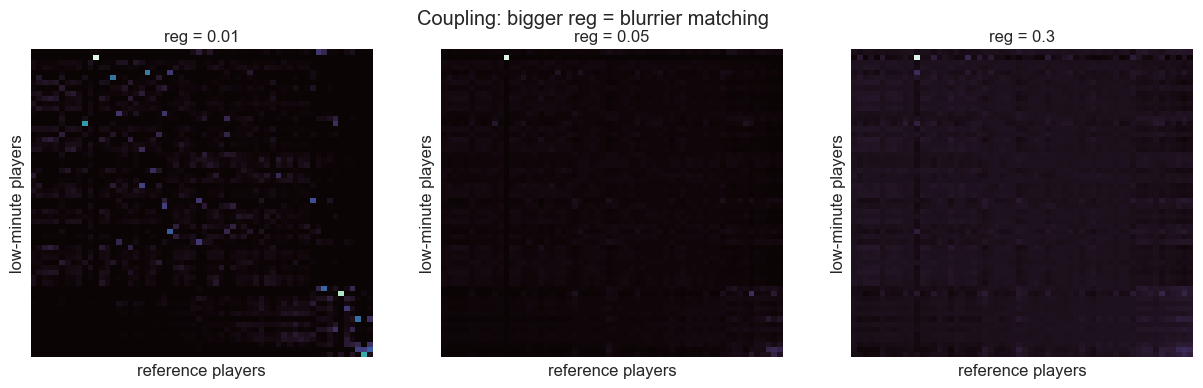

In [4]:
mean, std = reference.mean(), reference.std()
sample_low = d.raw.loc[rows].sample(60, random_state=0).sort_values(STAT)
sample_ref = reference.sample(60, random_state=0).sort_values(STAT)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, reg in zip(axes, [0.01, 0.05, 0.3]):
    coupling = otm.sinkhorn_coupling(((sample_low - mean) / std).to_numpy(),
                                     ((sample_ref - mean) / std).to_numpy(), reg)
    sns.heatmap(coupling, cmap="mako", ax=ax, cbar=False, xticklabels=False, yticklabels=False)
    ax.set_title(f"reg = {reg}"); ax.set_xlabel("reference players"); ax.set_ylabel("low-minute players")
plt.suptitle("Coupling: bigger reg = blurrier matching")
plt.show()

Now the movement in 2-D. We squash all stats into two directions with PCA just for drawing.
Each arrow starts at a low-minute player's raw profile and ends at where Sinkhorn sends them. Grey dots are the reference.

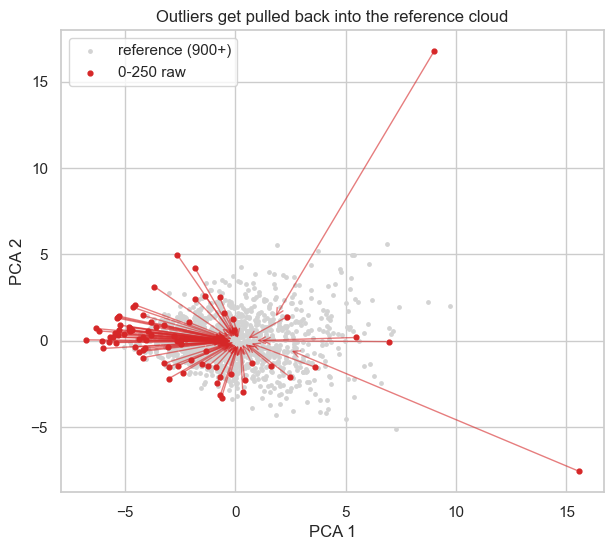

In [5]:
moved = otm.transport_sinkhorn(d.raw.loc[rows], reference, reg=0.05)

pca = PCA(n_components=2).fit((reference - mean) / std)
start = pca.transform((d.raw.loc[rows] - mean) / std)
end = pca.transform((moved - mean) / std)
ref_2d = pca.transform((reference - mean) / std)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(*ref_2d.T, s=6, color="lightgrey", label="reference (900+)")
pick = np.random.default_rng(0).choice(len(rows), size=min(80, len(rows)), replace=False)
for a, b in zip(start[pick], end[pick]):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="tab:red", alpha=0.6))
ax.scatter(*start[pick].T, s=12, color="tab:red", label=f"{low_bucket} raw")
ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2"); ax.legend(); ax.set_title("Outliers get pulled back into the reference cloud")
plt.show()

# Part B: every position group

We score each estimate against the same player's per-90 rate the *following* year (players with 600+ minutes next year).
Lower RMSE and higher Spearman are better. The heatmaps show the gain over using the raw number.

In [6]:
BUCKET_COLUMNS = ["all"] + common.BUCKET_LABELS


def score_matrix(results: dict, method: str, metric: str) -> pd.DataFrame:
    """Rows = position groups, columns = minute buckets: how much `method` beats raw.

    For RMSE the number is the percent drop in error; for Spearman it is the change in
    correlation. In both cases positive means better than raw.
    """
    rows = {}
    for group, scores in results.items():
        before, after = scores["raw"][metric], scores[method][metric]
        rows[group] = (before - after) / before * 100 if metric == "rmse" else after - before
    return pd.DataFrame(rows).T.reindex(columns=BUCKET_COLUMNS)


def plot_gain(results: dict, methods: list):
    """One heatmap pair (RMSE gain, Spearman gain) per method."""
    fig, axes = plt.subplots(len(methods), 2, figsize=(14, 4.2 * len(methods)), squeeze=False)
    for row, method in zip(axes, methods):
        for ax, metric, fmt, title in zip(row, ["rmse", "spearman"], [".0f", ".2f"],
                                          ["% drop in RMSE vs raw", "change in Spearman vs raw"]):
            matrix = score_matrix(results, method, metric)
            limit = np.nanmax(np.abs(matrix.to_numpy()))
            sns.heatmap(matrix, annot=True, fmt=fmt, cmap="RdYlGn", center=0, vmin=-limit, vmax=limit,
                        cbar=False, ax=ax)
            ax.set_title(f"{method}: {title} (green = better)")
            ax.set_xlabel("Minutes played in season t"); ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

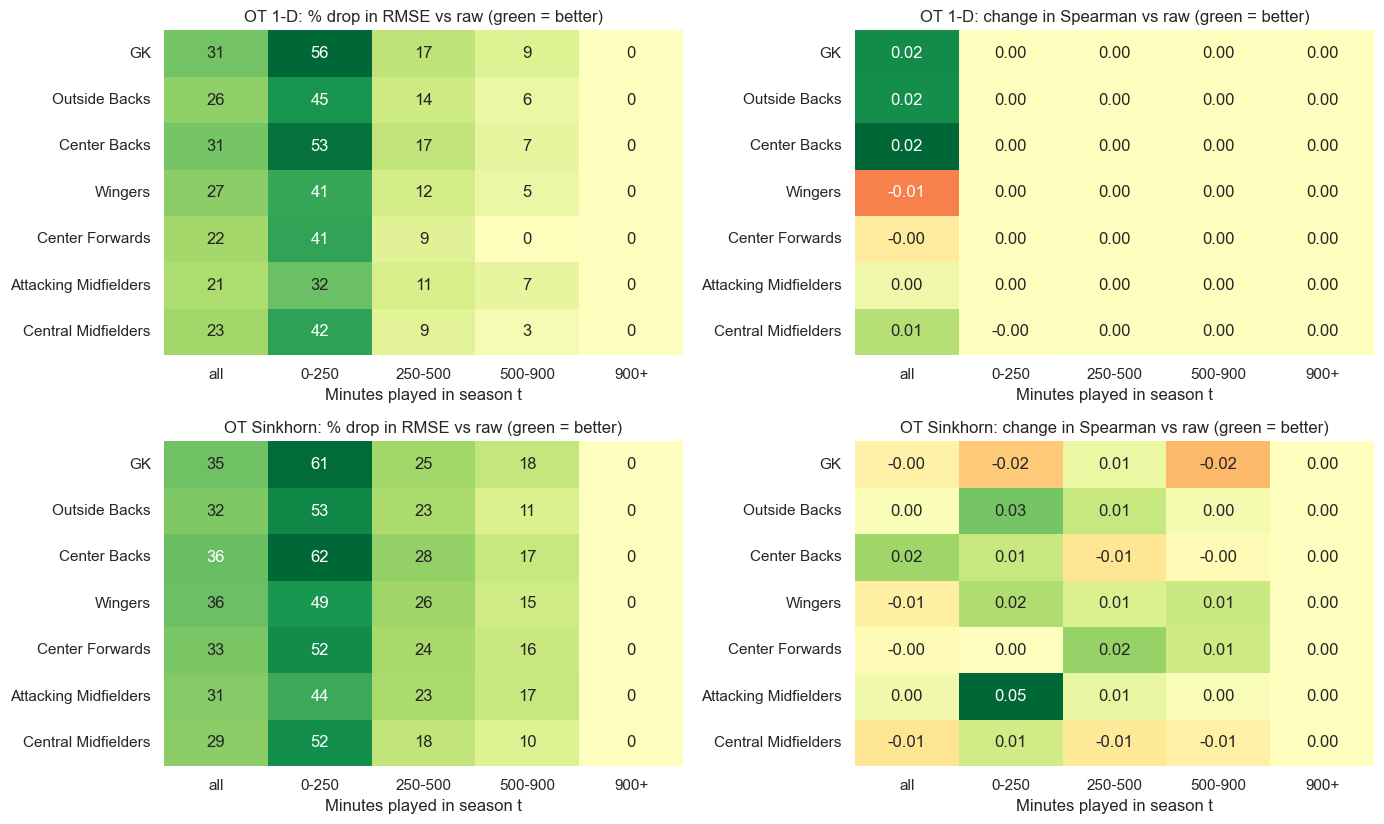

In [7]:
references = {g: otm.fit_reference(d.all_rates, d.terms["minutes"]) for g, d in data.items()}

results = {}
for group, d in data.items():
    one_d = otm.transport_low_minutes(d.raw, d.minutes, references[group], how="1d")
    sinkhorn = otm.transport_low_minutes(d.raw, d.minutes, references[group], how="sinkhorn")
    results[group] = {"raw": common.evaluate(d.raw, d.target, d.minutes),
                      "OT 1-D": common.evaluate(one_d, d.target, d.minutes),
                      "OT Sinkhorn": common.evaluate(sinkhorn, d.target, d.minutes)}
plot_gain(results, ["OT 1-D", "OT Sinkhorn"])

In [8]:
# The same numbers as a table.
pd.concat({g: pd.concat(r, names=["method"]) for g, r in results.items()}, names=["group"]).round(3)

n  spearman   rmse
group               method      bucket                        
GK                  raw         all      1387     0.451  1.427
                                0-250     253     0.331  2.533
                                250-500   132     0.401  1.330
                                500-900   195     0.415  1.153
                                900+      807     0.538  0.893
...                                       ...       ...    ...
Central Midfielders OT Sinkhorn all      3098     0.500  0.878
                                0-250     633     0.305  0.996
                                250-500   544     0.485  0.896
                                500-900   743     0.561  0.834
                                900+     1178     0.628  0.824

[105 rows x 3 columns]

## B1. How blurry should the matching be? (`reg`)

Small `reg` follows each player's raw numbers closely. Large `reg` sends everybody to the average.
Each line is one position group; the y-axis is the overall RMSE relative to raw (below 1 = better than raw).

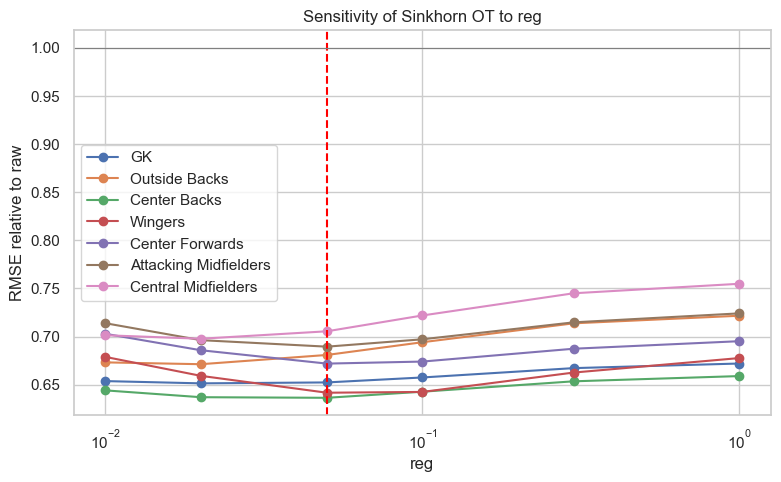

In [9]:
regs = [0.01, 0.02, 0.05, 0.1, 0.3, 1.0]
scan = {}
for group, d in data.items():
    base = common.evaluate(d.raw, d.target, d.minutes).loc["all", "rmse"]
    scan[group] = [common.evaluate(otm.transport_low_minutes(d.raw, d.minutes, references[group], "sinkhorn", reg),
                                   d.target, d.minutes).loc["all", "rmse"] / base for reg in regs]
scan = pd.DataFrame(scan, index=regs)

fig, ax = plt.subplots(figsize=(9, 5))
scan.plot(marker="o", ax=ax, logx=True)
ax.axvline(0.05, color="red", linestyle="--", label="default reg"); ax.axhline(1, color="grey", linewidth=0.8)
ax.set_xlabel("reg"); ax.set_ylabel("RMSE relative to raw"); ax.set_title("Sensitivity of Sinkhorn OT to reg")
plt.show()

## Takeaways

Female players, scored against next season. "Drop in RMSE" is relative to using the raw per-90.

* **Both OT versions cut error in every group.** Overall RMSE drops 21-31% with 1-D OT and 29-36% with Sinkhorn OT. Players with 900+ minutes are left alone by design, so their column is 0.
* **Sinkhorn beats 1-D OT in every group.** Using all stats together matters most in the 250-900 minute buckets, for example Wingers at 500-900 minutes: 15% drop vs 5%.
* **1-D OT cannot change the order of players inside a bucket**, so its Spearman is unchanged there by construction. Sinkhorn can, and its Spearman changes are small and mixed (from -0.02 to +0.05), so this run gives no clear ranking gain.
* **Compared with shrinkage (notebook 01):** about equal overall. Shrinkage is as good or better for Center Backs and GK under 250 minutes; Sinkhorn is better at 250-900 minutes and a little better for Wingers and Attacking Midfielders.
* **`reg` is not very sensitive.** Values from 0.02 to 0.1 are all close to the best in every group, so the default of 0.05 is reasonable.
* **Limit:** OT assumes low-minute players are as good on average as the reference players (900+ minutes). If coaches play weaker players less, low-minute players are probably worse, and OT will overrate them slightly.